# Covariance and Correlation

*Connect covariance and Pearson correlation to centered vectors and recognize the limits of linear association.*


## Paired Deviations Describe Joint Movement

Each row must pair measurements from the same observation. For a sample,

$$s_{xy}=\frac{1}{n-1}\sum_i(x_i-\bar{x})(y_i-\bar{y}).$$

Products are positive when both deviations have the same sign and negative
when their signs differ. Covariance has the product of the two variables'
units, so its magnitude depends on measurement scale.


In [1]:
import numpy as np
import pandas as pd

study_hours = np.array([1, 2, 3, 4, 5], dtype=float)
practice_count = np.array([2, 1, 4, 3, 5], dtype=float)
centered_study = study_hours - study_hours.mean()
centered_practice = practice_count - practice_count.mean()
sample_covariance = np.dot(centered_study, centered_practice) / (len(study_hours) - 1)
print(
    pd.DataFrame(
        {
            "study_hours": study_hours,
            "practice_count": practice_count,
            "study_deviation": centered_study,
            "practice_deviation": centered_practice,
            "deviation_product": centered_study * centered_practice,
        }
    ).to_string(index=False)
)
print("Sample covariance:", sample_covariance)


 study_hours  practice_count  study_deviation  practice_deviation  deviation_product
         1.0             2.0             -2.0                -1.0                2.0
         2.0             1.0             -1.0                -2.0                2.0
         3.0             4.0              0.0                 1.0                0.0
         4.0             3.0              1.0                 0.0                0.0
         5.0             5.0              2.0                 2.0                4.0
Sample covariance: 2.0


The deviation products sum to 8, giving sample covariance 2. The positive
sign indicates an overall tendency for larger study values to pair with larger
practice values in these five records.


## Pearson Correlation Removes the Measurement Scale

For nonconstant paired variables, $r=s_{xy}/(s_xs_y)$ is dimensionless and lies
between -1 and 1. Values +1 and -1 represent perfect increasing and decreasing
linear relationships; values near zero indicate weak linear association.
Multiplying one variable by a positive unit-conversion factor changes covariance
but leaves correlation unchanged.


In [2]:
correlation = sample_covariance / (study_hours.std(ddof=1) * practice_count.std(ddof=1))
print("Pearson correlation:", round(correlation, 4))
print("NumPy correlation:", round(np.corrcoef(study_hours, practice_count)[0, 1], 4))
print(
    "Covariance after converting hours to minutes:",
    np.cov(study_hours * 60, practice_count, ddof=1)[0, 1],
)
print(
    "Correlation after conversion:",
    round(np.corrcoef(study_hours * 60, practice_count)[0, 1], 4),
)


Pearson correlation: 0.8
NumPy correlation: 0.8
Covariance after converting hours to minutes: 120.0
Correlation after conversion: 0.8


Correlation is 0.8. Converting hours to minutes multiplies covariance by
60, from 2 to 120, but correlation remains 0.8.


## Correlation Is the Cosine Between Centered Vectors

Let $\mathbf d_x=(x_1-\bar{x},\ldots,x_n-\bar{x})$ and define
$\mathbf d_y$ in the same way. Since $s_x=\|\mathbf d_x\|/\sqrt{n-1}$,
the sample factors cancel:

$$r=\frac{\mathbf d_x\cdot\mathbf d_y}{\|\mathbf d_x\|\,\|\mathbf d_y\|}
=\cos\theta.$$

These vectors have one coordinate per observation. They are not individual
two-dimensional points in a scatterplot. Centering is essential; cosine
similarity of the raw vectors is generally a different number.


In [3]:
centered_cosine = np.dot(centered_study, centered_practice) / (
    np.linalg.norm(centered_study) * np.linalg.norm(centered_practice)
)
raw_cosine = np.dot(study_hours, practice_count) / (
    np.linalg.norm(study_hours) * np.linalg.norm(practice_count)
)
print("Centered-vector cosine:", round(centered_cosine, 4))
print("Raw-vector cosine:", round(raw_cosine, 4))
print("Centered cosine equals Pearson r:", np.isclose(centered_cosine, correlation))


Centered-vector cosine: 0.8
Raw-vector cosine: 0.9636
Centered cosine equals Pearson r: True


The centered cosine is 0.8, matching Pearson correlation. The raw-vector
cosine is about 0.9636 and measures a different relationship because it retains
the offsets from zero.


## Zero Correlation Can Coexist with a Strong Relationship

The deterministic relation `y = x ** 2` is nonlinear. Symmetric positive and
negative x values make their signed covariance contributions cancel.
A scatterplot exposes this structure even when Pearson correlation is zero.


Quadratic-data Pearson correlation: 0.0


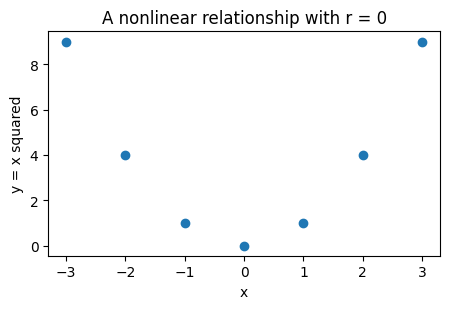

In [4]:
import matplotlib.pyplot as plt

x_values = np.arange(-3, 4, dtype=float)
y_values = x_values**2
print(
    "Quadratic-data Pearson correlation:",
    round(np.corrcoef(x_values, y_values)[0, 1], 4),
)
fig, ax = plt.subplots(figsize=(4.6, 3.2), dpi=100)
ax.scatter(x_values, y_values)
ax.set(xlabel="x", ylabel="y = x squared", title="A nonlinear relationship with r = 0")
fig.tight_layout()
plt.show()
plt.close(fig)


Every y value is determined by x, yet Pearson correlation is zero. At the
population level, independence implies zero correlation when variances are
finite and nonzero; zero correlation does not imply independence. A sample
correlation can also fluctuate around its population value.


Keep paired observations aligned and inspect their scatterplot. Correlation summarizes linear association, is undefined for constant variables, and does not establish causation.

[Related explanation in the source lecture](https://www.youtube.com/watch?v=9bM65kxOwPA&t=2977s).
